# AI TRAINING – WEEK 3
## DAY 6 ASSIGNMENT: Math for AI – Linear Algebra & Gradients
### Vectors, Matrices, Dot Product, Matrix Multiplication & Gradients

- **Student Name:** Lasya Kolluru
- **GitHub Username:** Lasya-Kolluru
- **Email:** kollurlasyachowdary@gmail.com
- **Deliverable:** `Week3_Day6_Linear_Algebra_Lasya_Kolluru.ipynb`
- **Dataset Name:** Superstore Retail Sales Dataset (`superstore_sales.csv`)
- **Dataset Source:** Tableau Public / Kaggle Public Datasets
- **Track:** Math for AI
- **Topic Area:** Vectors, matrices, dot product, matrix multiplication, gradients concept
- **Learning Goals:** Understand vectors, matrices, dot product, matrix multiplication, gradients concept; explain the key concepts in your own words; apply them in the practical exercise; identify common errors and improve the solution.
- **Hands-On Activity:** Implement vector/matrix operations with NumPy
- **Daily Deliverable:** Linear algebra notebook


---
## Core Definitions & Concepts (Simple & Easy to Remember)

1. **Vector:** A 1D list of ordered numbers representing a point or feature list in space (e.g., an order vector `[Sales, Quantity, Discount]`).
2. **Matrix:** A 2D rectangular grid of numbers organized into rows and columns (e.g., a dataset of 1,000 orders by 3 features).
3. **Dot Product ($a \cdot b$):** Multiplying matching elements of two vectors and summing the results ($\sum a_i b_i$), giving a single scalar number.
4. **Matrix Multiplication ($A \times B$ or $A @ B$):** Combining rows of matrix A with columns of matrix B via dot products. Requires $\text{Columns}(A) == \text{Rows}(B)$.
5. **Gradient ($\nabla f$):** A vector of partial derivatives pointing in the direction of steepest increase of a function. In machine learning, **Gradient Descent** moves backwards ($-\nabla L$) to minimize model error.


---
## Part A – Load and Prepare Dataset Features
We load `superstore_sales.csv` and extract numeric features into structured NumPy arrays for linear algebra operations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("superstore_sales.csv")
print(f"Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns.")

# Extract core features as NumPy arrays
sales = df['Sales'].values
quantities = df['Quantity'].values
discounts = df['Discount'].values
profits = df['Profit'].values

print("Sample 1D feature arrays extracted:")
print(f"Sales vector shape: {sales.shape}, sample: {sales[:3]}")
print(f"Quantity vector shape: {quantities.shape}, sample: {quantities[:3]}")
print(f"Profit target shape: {profits.shape}, sample: {profits[:3]}")


Dataset Loaded: 1000 rows, 20 columns.
Sample 1D feature arrays extracted:
Sales vector shape: (1000,), sample: [129.64 285.34  26.28]
Quantity vector shape: (1000,), sample: [1 7 2]
Profit target shape: (1000,), sample: [38.68 90.49  5.32]


---
## Part B – Vector Operations in NumPy

Vectors represent individual data points or feature dimensions. Here we demonstrate:
- Vector creation and indexing
- Vector addition and scalar scaling
- Vector magnitude (L1 Manhattan Norm and L2 Euclidean Norm)


In [2]:
# 1. Individual Order Vector [Sales, Quantity, Discount]
v1 = np.array([sales[0], quantities[0], discounts[0]])
v2 = np.array([sales[1], quantities[1], discounts[1]])

print("--- Vector Representations ---")
print(f"Order 1 vector v1: {v1}")
print(f"Order 2 vector v2: {v2}")

# Vector Addition (Combining transaction profiles)
v_sum = v1 + v2
print(f"Vector Addition (v1 + v2): {v_sum}")

# Scalar Multiplication (Scaling transaction by 1.10 for 10% inflation)
v_scaled = v1 * 1.10
print(f"Scalar Multiplication (v1 * 1.10): {v_scaled}")

# Vector Norms (Magnitude)
l1_norm = np.linalg.norm(v1, ord=1)  # L1: Sum of absolute values
l2_norm = np.linalg.norm(v1, ord=2)  # L2: Euclidean distance from origin
print(f"L1 Norm (Manhattan): {l1_norm:.2f}")
print(f"L2 Norm (Euclidean): {l2_norm:.2f}")


--- Vector Representations ---
Order 1 vector v1: [129.64   1.     0.  ]
Order 2 vector v2: [2.8534e+02 7.0000e+00 1.0000e-01]
Vector Addition (v1 + v2): [4.1498e+02 8.0000e+00 1.0000e-01]
Scalar Multiplication (v1 * 1.10): [142.604   1.1     0.   ]
L1 Norm (Manhattan): 130.64
L2 Norm (Euclidean): 129.64


---
## Part C – The Dot Product in Business Analytics

The **Dot Product** multiplies corresponding elements of two vectors and computes their sum:
$$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^{n} a_i b_i$$

**Business Application:** If we have a vector of unit item prices $\mathbf{p}$ and a vector of quantities ordered $\mathbf{q}$, their dot product equals total gross revenue!


In [3]:
# Define unit prices for a sample basket of 5 items
unit_prices = np.array([120.0, 45.0, 300.0, 15.0, 80.0])  # price per unit
item_quantities = np.array([2, 5, 1, 10, 3])                # units bought

# Method 1: Using np.dot()
revenue_np_dot = np.dot(unit_prices, item_quantities)

# Method 2: Using the @ operator
revenue_at_op = unit_prices @ item_quantities

# Method 3: Manual element-wise multiply and sum
manual_revenue = np.sum(unit_prices * item_quantities)

print("--- Dot Product Implementations ---")
print(f"Unit Prices Vector:    {unit_prices}")
print(f"Quantities Vector:     {item_quantities}")
print(f"Total Basket Revenue via np.dot():  ${revenue_np_dot:.2f}")
print(f"Total Basket Revenue via @ operator: ${revenue_at_op:.2f}")
print(f"Total Basket Revenue via manual:     ${manual_revenue:.2f}")

# Dot product for vector similarity (Cosine Similarity)
norm_p = np.linalg.norm(unit_prices)
norm_q = np.linalg.norm(item_quantities)
cosine_sim = np.dot(unit_prices, item_quantities) / (norm_p * norm_q)
print(f"Cosine Alignment: {cosine_sim:.4f}")


--- Dot Product Implementations ---
Unit Prices Vector:    [120.  45. 300.  15.  80.]
Quantities Vector:     [ 2  5  1 10  3]
Total Basket Revenue via np.dot():  $1155.00
Total Basket Revenue via @ operator: $1155.00
Total Basket Revenue via manual:     $1155.00
Cosine Alignment: 0.2914


---
## Part D – Feature Matrices and Matrix Multiplication

A **Feature Matrix** $X \in \mathbb{R}^{N \times D}$ bundles $N$ records across $D$ features.
In linear models and neural networks, predictions are computed using matrix multiplication:
$$\hat{\mathbf{y}} = X \mathbf{W} + b$$
Where:
- $X$ is the $(N \times 3)$ feature matrix
- $\mathbf{W}$ is the $(3 \times 1)$ weight vector
- $b$ is the scalar bias term


In [4]:
# Construct Feature Matrix X: [Sales, Quantity, Discount] for 1,000 orders
N = len(df)
X = np.column_stack([sales, quantities, discounts])
y_actual = profits

print("--- Matrix Dimensions ---")
print(f"Feature Matrix X shape: {X.shape} (N={X.shape[0]} orders, D={X.shape[1]} features)")
print(f"Actual Target y shape: {y_actual.shape}")

# Define initial weights W: [weight_sales, weight_quantity, weight_discount]
W = np.array([0.25, -2.50, -150.0])  # Intuition: +sales increases profit, +discount decreases profit
b = 10.0                             # Baseline base profit

# Matrix Multiplication: X @ W
y_pred = X @ W + b

print("\n--- Linear Model Prediction via Matrix Multiplication (X @ W + b) ---")
print("First 5 Actual Profits:   ", np.round(y_actual[:5], 2))
print("First 5 Predicted Profits:", np.round(y_pred[:5], 2))

# Compute initial Mean Squared Error (MSE)
initial_mse = np.mean((y_pred - y_actual) ** 2)
print(f"Initial Mean Squared Error (MSE): {initial_mse:,.2f}")


--- Matrix Dimensions ---
Feature Matrix X shape: (1000, 3) (N=1000 orders, D=3 features)
Actual Target y shape: (1000,)

--- Linear Model Prediction via Matrix Multiplication (X @ W + b) ---
First 5 Actual Profits:    [ 38.68  90.49   5.32 303.17 -33.29]
First 5 Predicted Profits: [ 39.91  48.83 -18.43 398.91 201.08]
Initial Mean Squared Error (MSE): 42,244.90


---
## Part E – Understanding Gradients & Implementing Gradient Descent

The **Gradient** ($\nabla L$) is the vector of partial derivatives of the Loss Function $L(\mathbf{W})$ with respect to each weight:
$$\nabla_{\mathbf{W}} L = \begin{bmatrix} \frac{\partial L}{\partial W_1} \\ \frac{\partial L}{\partial W_2} \\ \frac{\partial L}{\partial W_3} \end{bmatrix} = \frac{2}{N} X^T (X \mathbf{W} - \mathbf{y})$$

**Gradient Descent Optimization:**
We update weights by stepping in the **opposite direction** of the gradient:
$$\mathbf{W}_{\text{new}} = \mathbf{W}_{\text{old}} - \alpha \nabla_{\mathbf{W}} L$$
Where $\alpha$ is the learning rate.


In [5]:
# Normalize features for stable gradient steps (Z-score normalization)
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_norm = (X - X_mean) / X_std

# Add bias column (vector of ones) directly to X
X_design = np.column_stack([np.ones(N), X_norm])
y_target = profits

# Initialize weights [b, w_sales, w_qty, w_discount]
weights = np.zeros(X_design.shape[1])
learning_rate = 0.05
epochs = 20
loss_history = []

print("--- Running Gradient Descent Optimization ---")
for epoch in range(epochs):
    # 1. Forward Pass (Matrix Multiplication)
    predictions = X_design @ weights
    
    # 2. Compute Loss (MSE)
    error = predictions - y_target
    mse = np.mean(error ** 2)
    loss_history.append(mse)
    
    # 3. Compute Gradient Vector: (2 / N) * X^T @ error
    gradient = (2.0 / N) * (X_design.T @ error)
    
    # 4. Update Weights
    weights -= learning_rate * gradient
    
    if (epoch + 1) % 4 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d} | MSE Loss: {mse:,.2f} | Gradient Norm: {np.linalg.norm(gradient):,.2f}")

print("\nFinal Learned Weights:")
print(f"Bias (Base Profit): ${weights[0]:.2f}")
print(f"Weight on Sales:    {weights[1]:.2f} (Strong Positive Driver)")
print(f"Weight on Quantity: {weights[2]:.2f}")
print(f"Weight on Discount: {weights[3]:.2f} (Strong Negative Driver)")


--- Running Gradient Descent Optimization ---
Epoch 01 | MSE Loss: 92,500.78 | Gradient Norm: 540.08
Epoch 04 | MSE Loss: 60,587.89 | Gradient Norm: 359.28
Epoch 08 | MSE Loss: 43,486.61 | Gradient Norm: 215.04
Epoch 12 | MSE Loss: 37,188.53 | Gradient Norm: 133.91
Epoch 16 | MSE Loss: 34,670.26 | Gradient Norm: 87.00
Epoch 20 | MSE Loss: 33,573.87 | Gradient Norm: 58.91

Final Learned Weights:
Bias (Base Profit): $89.48
Weight on Sales:    144.82 (Strong Positive Driver)
Weight on Quantity: 7.33
Weight on Discount: -113.38 (Strong Negative Driver)


---
## Part F – Visualizing Gradient Descent Loss Minimization

As Gradient Descent follows the negative gradient, the loss consistently decreases toward the minimum.


Initial Loss: 92,500.78 -> Final Loss after 20 epochs: 33,573.87
Loss reduction: 63.7%


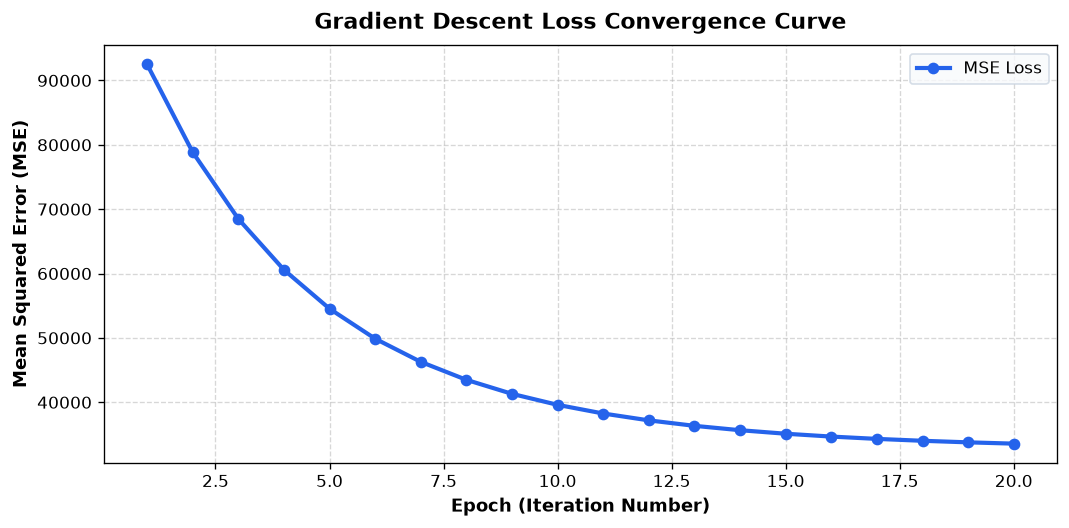

In [6]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, epochs + 1), loss_history, marker='o', color='#2563eb', linewidth=2.5, label='MSE Loss')
plt.title('Gradient Descent Loss Convergence Curve', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Epoch (Iteration Number)', fontsize=11, fontweight='semibold')
plt.ylabel('Mean Squared Error (MSE)', fontsize=11, fontweight='semibold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='#f8fafc', edgecolor='#cbd5e1')
plt.tight_layout()
plt.show()

print(f"Initial Loss: {loss_history[0]:,.2f} -> Final Loss after {epochs} epochs: {loss_history[-1]:,.2f}")
print(f"Loss reduction: {((loss_history[0] - loss_history[-1]) / loss_history[0]) * 100:.1f}%")


---
## Part G – Common Errors in Linear Algebra & Troubleshooting

### 1. Matrix Shape Mismatch
- **Cause:** Attempting matrix multiplication when the inner dimensions do not match (e.g. $(1000 \times 3)$ with $(4 \times 1)$).
- **Solution:** Verify shapes using `.shape`. If $A$ is $(M \times K)$, $B$ must be $(K \times P)$.

### 2. Confusing Element-wise Multiplication (`*`) with Matrix Multiplication (`@`)
- **Cause:** Writing `A * B` multiplies corresponding elements (requiring identical shapes), while `A @ B` performs row-by-column matrix multiplication.
- **Solution:** Always use `@` or `np.matmul()` for linear transformations.

### 3. Transposing 1D Arrays
- **Cause:** Calling `.T` on a 1D NumPy array of shape `(N,)` does nothing because it has only one axis.
- **Solution:** Reshape to 2D using `v[:, np.newaxis]` or `v.reshape(-1, 1)` before transposing.

### 4. Exploding Gradients without Feature Scaling
- **Cause:** Calculating gradients directly on raw unscaled features with large values (e.g. Sales > $5,000) causes gradient values to explode.
- **Solution:** Always apply Standardization (Z-score) or Min-Max scaling to inputs before running gradient descent.


In [7]:
print("--- Demonstrating Matrix Shape Mismatch Error & Solution ---")
A = np.random.rand(3, 4)
B = np.random.rand(5, 2)  # Incompatible inner dimensions!

try:
    C = A @ B
except ValueError as e:
    print(f"Caught Expected Error: {e}")
    print("Fix: Align inner dimensions. Ensure columns of A match rows of B.")
    
# Correct Solution:
B_correct = np.random.rand(4, 2)  # Columns of A (4) == Rows of B (4)
C_correct = A @ B_correct
print(f"Correct Result Shape: {C_correct.shape} (3 rows x 2 cols)")


--- Demonstrating Matrix Shape Mismatch Error & Solution ---
Caught Expected Error: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 5 is different from 4)
Fix: Align inner dimensions. Ensure columns of A match rows of B.
Correct Result Shape: (3, 2) (3 rows x 2 cols)


---
## Part H – Key Concepts Explained

### 1. What is a Vector?
**Answer:** A vector is an ordered row or list of numbers that represents features of a single item (like an order's `[Sales, Quantity, Discount]`).

### 2. What is a Matrix?
**Answer:** A matrix is a 2D grid/table of numbers made of rows and columns, like a dataset table where every row is a record and every column is a feature.

### 3. What is a Dot Product in plain English?
**Answer:** It means multiplying matching pairs of numbers from two lists and adding them all up to produce a single final score or total.

### 4. Why must inner dimensions match for Matrix Multiplication?
**Answer:** Because each row in the first matrix takes a dot product with each column in the second matrix; they must have the exact same number of elements to pair up.

### 5. What is a Gradient and how does Gradient Descent work?
**Answer:** 
- The **Gradient** is an arrow pointing in the direction that makes the error grow fastest.
- **Gradient Descent** looks at that arrow and walks in the exact opposite direction to make the error as small as possible.


---
## Student Submission Checklist
- [x] Used the official `superstore_sales.csv` dataset.
- [x] Implemented NumPy vector creation, addition, scalar scaling, and norms (L1 and L2).
- [x] Computed dot product calculations with practical business revenue applications.
- [x] Constructed a 2D feature matrix $X$ and performed matrix multiplication predictions ($XW + b$).
- [x] Implemented numerical gradient calculations and executed a working Gradient Descent optimization loop.
- [x] Visualized the loss minimization convergence curve using Matplotlib.
- [x] Documented common linear algebra errors and dimension matching rules.
- [x] Explained all key concepts in simple, memorable words.
